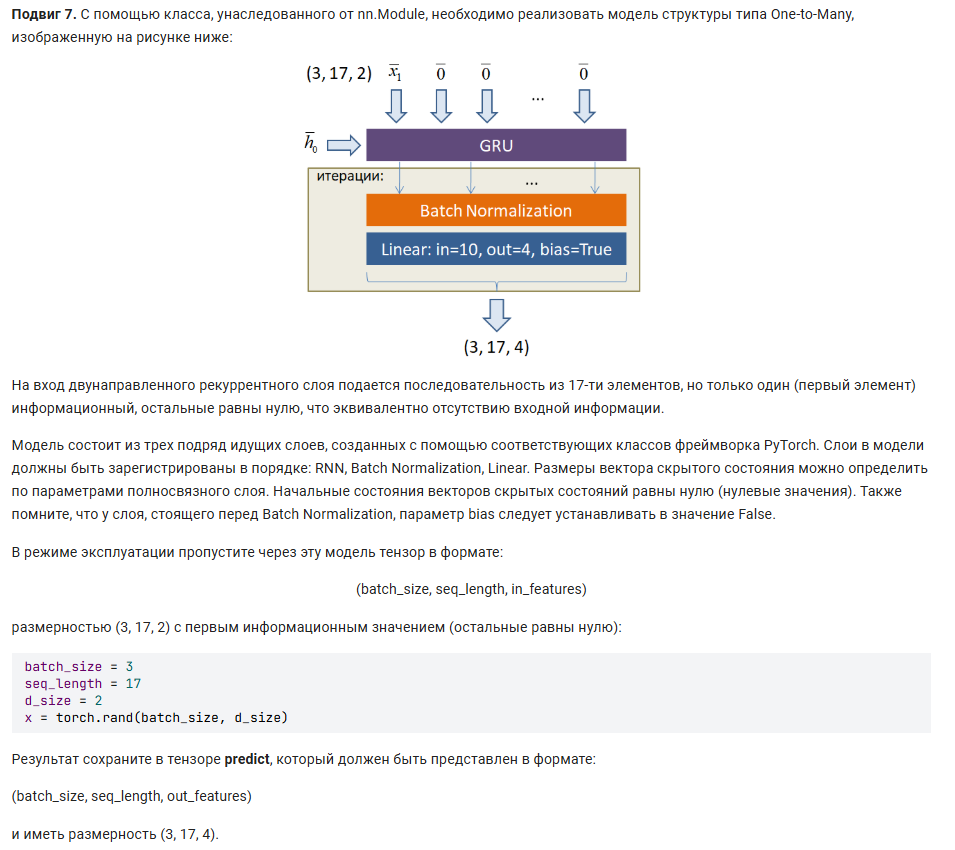

In [10]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(input_size=2, hidden_size=5, bias=False, batch_first=True, bidirectional=True)
        self.bn = nn.BatchNorm1d(10)
        self.linear = nn.Linear(10, 4)

    def forward(self, x):
        y, _ = self.gru(x)
        seq_length = y.shape[1]
        res = []
        for i in range(seq_length):
            out = self.bn(y[:, i, :])
            out = self.linear(out)
            res.append(out)
        res = torch.stack(res, dim=1)
        return res

# тензор x в программе не менять
batch_size = 3
seq_length = 17
d_size = 2
x = torch.rand(batch_size, d_size)
u = torch.zeros(batch_size, seq_length, d_size)
u[:, 0, :] = x

model = MyNet() # здесь создавайте объект модели
model.eval()

# здесь продолжайте программу
predict = model(u)
predict

tensor([[[-0.0578,  0.1616,  0.2413,  0.1355],
         [-0.0354,  0.0916,  0.2727,  0.1149],
         [-0.0349,  0.0822,  0.2675,  0.0990],
         [-0.0344,  0.0776,  0.2647,  0.0909],
         [-0.0339,  0.0754,  0.2632,  0.0866],
         [-0.0335,  0.0743,  0.2624,  0.0843],
         [-0.0332,  0.0738,  0.2619,  0.0831],
         [-0.0330,  0.0736,  0.2617,  0.0824],
         [-0.0329,  0.0735,  0.2616,  0.0821],
         [-0.0328,  0.0735,  0.2615,  0.0818],
         [-0.0328,  0.0735,  0.2615,  0.0817],
         [-0.0327,  0.0735,  0.2615,  0.0817],
         [-0.0327,  0.0735,  0.2615,  0.0816],
         [-0.0327,  0.0735,  0.2615,  0.0816],
         [-0.0327,  0.0735,  0.2615,  0.0816],
         [-0.0327,  0.0735,  0.2615,  0.0816],
         [-0.0327,  0.0735,  0.2615,  0.0816]],

        [[-0.0455,  0.0241,  0.2241,  0.1071],
         [-0.0410,  0.0510,  0.2492,  0.0963],
         [-0.0379,  0.0625,  0.2567,  0.0902],
         [-0.0357,  0.0682,  0.2597,  0.0864],
         [-